# Analyze High Frequency Word

# Setup and Load the Text

We start by importing the NLTK library and loading the raw words from the novel Emma. The gutenberg.words() command automatically tokenizes the text, meaning it splits the book into a list of individual words and punctuation marks.

In [31]:
import nltk
from nltk.corpus import gutenberg
nltk.download('gutenberg', quiet=True)

# Load the tokenized words from the novel
book_words = gutenberg.words('austen-emma.txt')
print("Total words loaded:", len(book_words))

Total words loaded: 192427


# Clean the Data (Remove Punctuation and Stopwords)

Raw text contains punctuation and common filler words that distort frequency analysis. Here we converts all words to lowercase, filters out non-alphabetical characters, and removes standard English stopwords to isolate the meaningful vocabulary.

In [32]:
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))

# Convert to lowercase and remove punctuation
clean_words = [word.lower() for word in book_words if word.isalpha()]

# Keep only the meaningful words
meaningful_words = [word for word in clean_words if word not in stop_words]
print("First 10 meaningful words:", meaningful_words[:10])

First 10 meaningful words: ['emma', 'jane', 'austen', 'volume', 'chapter', 'emma', 'woodhouse', 'handsome', 'clever', 'rich']


# Concordance (Keyword in Context)

Concordance displays the immediate surrounding context of a high-frequency word, showing exactly how the author uses it in a sentence rather than just plotting its location.

In [33]:
import nltk

# Create the NLTK Text object first
emma_text = nltk.Text(book_words)

# Now you can search for context
print("Context for 'Emma':")
emma_text.concordance("Emma", lines=5)

Context for 'Emma':
Displaying 5 of 865 matches:
                                   [ Emma by Jane Austen 1816 ] VOLUME I CHAPT
ane Austen 1816 ] VOLUME I CHAPTER I Emma Woodhouse , handsome , clever , and 
both daughters , but particularly of Emma . Between _them_ it was more the int
 friend very mutually attached , and Emma doing just what she liked ; highly e
r own . The real evils , indeed , of Emma ' s situation were the power of havi


# Collocations (Frequent Pairings)

While your previous code isolated and calculated raw frequencies for individual meaningful words, collocations identify specific two-word phrases that appear together unusually often in the text (e.g., "frank churchill" or "miss woodhouse").

In [34]:
print("Top Collocations in Emma:")
emma_text.collocations()

Top Collocations in Emma:
Frank Churchill; Miss Woodhouse; Miss Bates; Jane Fairfax; Miss
Fairfax; every thing; young man; every body; great deal; dare say;
John Knightley; Maple Grove; Miss Smith; Miss Taylor; Robert Martin;
Colonel Campbell; Box Hill; said Emma; Harriet Smith; William Larkins


# Calculate Frequencies and Visualize

After cleaning the dataset, we use FreqDist to count unique word occurrences and visualize the top 20 results using a line chart to immediately identify the most prominent terms in the text.

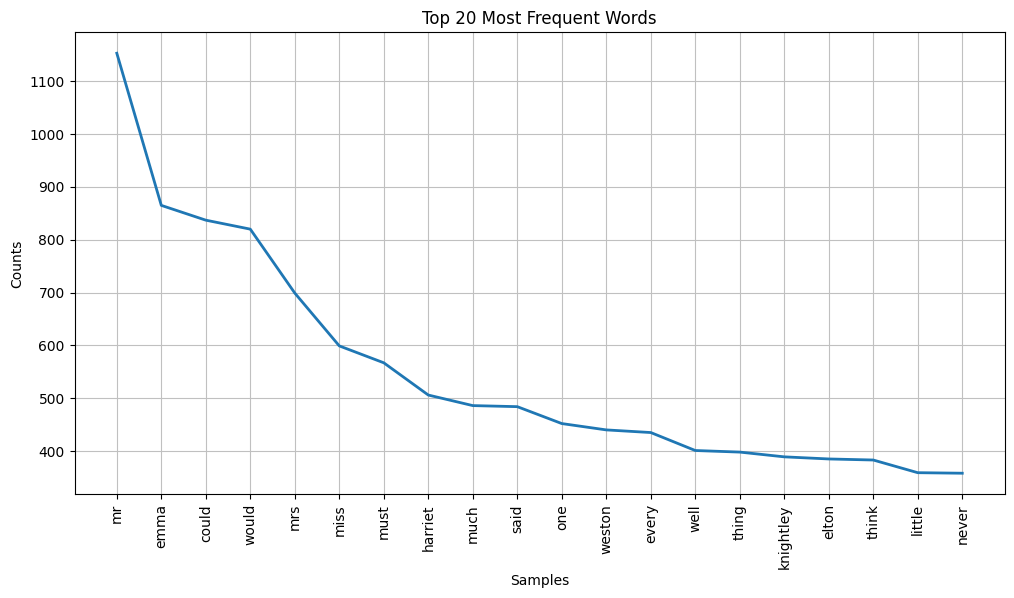

In [35]:
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

# Count the frequency of each meaningful word
word_frequencies = FreqDist(meaningful_words)

# Set up the chart dimensions for readability
plt.figure(figsize=(12, 6))

# Generate a line chart of the top 20 most frequent words
word_frequencies.plot(20, title="Top 20 Most Frequent Words")
plt.show()

# Cumulative Frequency Distributions

We can modify your existing FreqDist plot to show cumulative counts. This reveals what proportion of the entire novel is composed of just the top 20 to 50 most frequent words.

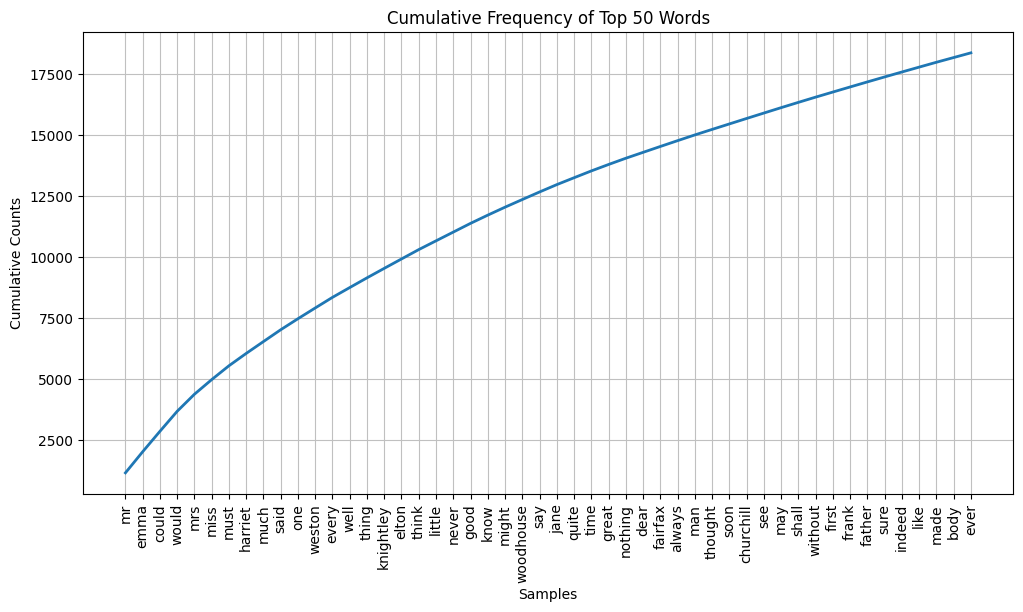

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
# Add the cumulative=True parameter to your existing plot command
word_frequencies.plot(50, cumulative=True, title="Cumulative Frequency of Top 50 Words")
plt.show()

# Lexical Dispersion Plot

A lexical dispersion plot is a visualization that maps the exact locations where specific words appear throughout a document's chronological progression.

This visualization maps exactly where specific high-frequency words appear from the first page to the last, helping us to spot narrative trends—such as a character only appearing in the second half of the book.

The provided lexical dispersion plot successfully maps the narrative arcs of four characters across the novel's approximately 190,000 words.   

The x-axis represents the text's chronological progression, while the blue vertical stripes indicate exactly where each name is mentioned.

The plot reveals distinct structural patterns:   Continuous Presence: "Emma" appears constantly from beginning to end, confirming her status as the central focus of the text.

"Knightley" is also present throughout the story, though with slightly more spacing between mentions.   

Late Introductions: "Frank" is virtually absent for the first 40,000 words before becoming a frequent subject in the middle and late stages of the novel.

 Similarly, "Jane" makes her primary entrance around the 60,000-word mark and appears in dense, concentrated clusters for the remainder of the book.   

<Figure size 1200x500 with 0 Axes>

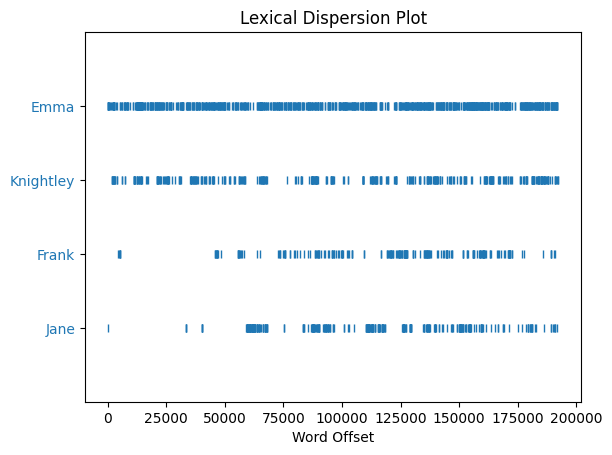

In [37]:
import nltk
import matplotlib.pyplot as plt

# Convert the raw word list into an NLTK Text object
emma_text = nltk.Text(book_words)

# Set the figure size for better readability
plt.figure(figsize=(12, 5))

# Generate the dispersion plot using exact capitalization
emma_text.dispersion_plot(["Emma", "Knightley", "Frank", "Jane"])
plt.show()

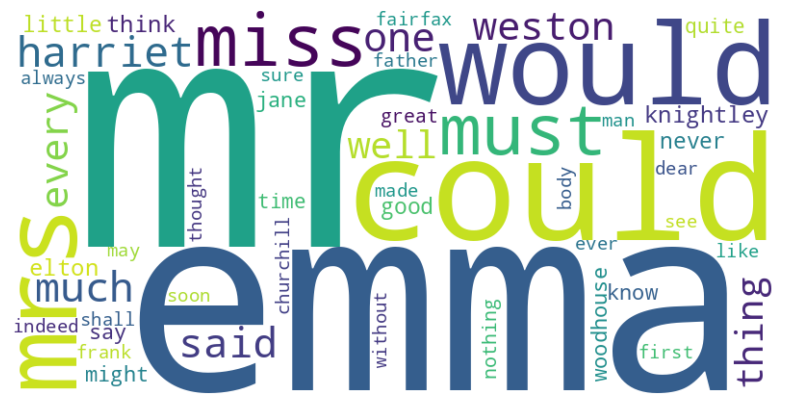

In [38]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Limit the word cloud to only the top 50 most frequent words
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=50).generate_from_frequencies(word_frequencies)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()